# Deep Learning PR 5 — Sentiment Analysis with RNN, LSTM and GRU
**Objective:** Build and compare an order-blind ANN baseline, SimpleRNN, LSTM, and GRU for positive/negative IMDB review classification.

**Dataset required:** `IMDB Dataset.csv` from [Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews). Keep it in the same folder as this notebook for the full 50K-review experiment.

This notebook uses manually written code cells, fixed random seeds, and saves plots in `plots/`. If the CSV is not present, it uses a small clearly labelled demo dataset so the notebook can still run end-to-end; demo metrics are not valid for the final submission.

In [1]:
import os, re, time, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, SimpleRNN, LSTM, GRU, RepeatVector
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_curve
from IPython.display import display, Markdown
os.makedirs('plots', exist_ok=True)
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)
warnings.filterwarnings('ignore')
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Text loading, cleaning, tokenisation and padding
**Objective:** Inspect and clean the raw reviews, remove duplicates before splitting, and prepare padded integer sequences.  
**Expected output:** Dataset checks, review-length plots, and train/test arrays.

In [2]:
DATA_PATH = 'IMDB Dataset.csv'
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    DEMO_MODE = False
else:
    print('WARNING: IMDB Dataset.csv not found. Using a small demo dataset only. Add the real Kaggle CSV and rerun for valid PR results.')
    positive = [
        'This movie was wonderful and beautifully acted',
        'I loved the story and the excellent performances',
        'A brilliant film with a moving ending',
        'Great direction and a very enjoyable movie',
        'The characters were warm and the story was touching',
        'Fantastic acting made this film memorable',
        'A clever funny and entertaining story',
        'The film was good and I would recommend it'
    ] * 8
    negative = [
        'This movie was boring and badly acted',
        'I hated the story and the terrible performances',
        'A dull film with a disappointing ending',
        'Poor direction made this movie unpleasant',
        'The characters were flat and the story was confusing',
        'Awful acting made this film forgettable',
        'A silly slow and irritating story',
        'The film was not good and I would not recommend it'
    ] * 8
    df = pd.DataFrame({'review': positive + negative, 'sentiment': ['positive']*len(positive)+['negative']*len(negative)})
print('Shape:', df.shape)
display(df.head())
print('\nClass balance:\n', df['sentiment'].value_counts(dropna=False))
print('\nNull counts:\n', df.isnull().sum())
print('\nTwo raw reviews:')
for review in df['review'].dropna().head(2):
    print(review, '\n---')

Shape: (128, 2)


,review,sentiment
0,This movie was wonderful and beautifully acted,positive
1,I loved the story and the excellent performances,positive
2,A brilliant film with a moving ending,positive
3,Great direction and a very enjoyable movie,positive
4,The characters were warm and the story was tou...,positive



Class balance:
 sentiment
positive    64
negative    64
Name: count, dtype: int64

Null counts:
 review       0
sentiment    0
dtype: int64

Two raw reviews:
This movie was wonderful and beautifully acted 
---
I loved the story and the excellent performances 
---


In [3]:
rows_before = len(df)
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().dropna(subset=['review', 'sentiment']).copy()
df['sentiment'] = df['sentiment'].astype(str).str.lower().str.strip()
df = df[df['sentiment'].isin(['positive', 'negative'])].copy()
print(f'Rows before cleaning: {rows_before}; exact duplicates: {duplicate_count}; rows after removal: {len(df)}')

Rows before cleaning: 128; exact duplicates: 112; rows after removal: 16


**Why remove duplicates before splitting?** If duplicate reviews enter both training and test sets, the model can effectively see test examples during training. This is data leakage and can inflate evaluation scores.

**Why preserve apostrophes and stop-words?** Apostrophes preserve contractions such as `don't`, and words such as `not` and `no` can reverse sentiment. Removing stop-words also damages the sequence and its meaning.

BEFORE: This movie was wonderful and beautifully acted

AFTER: this movie was wonderful and beautifully acted
Mean=7.4, median=7.0, 95th percentile=9.5


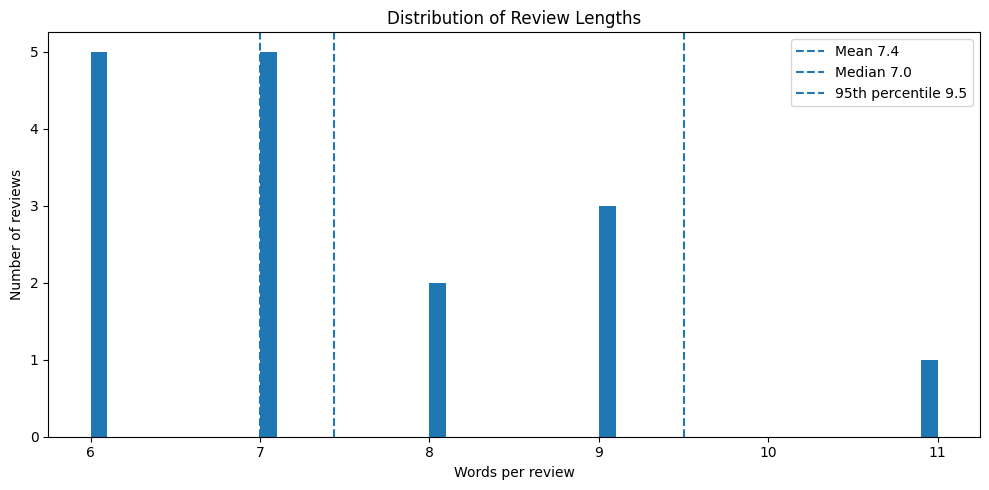

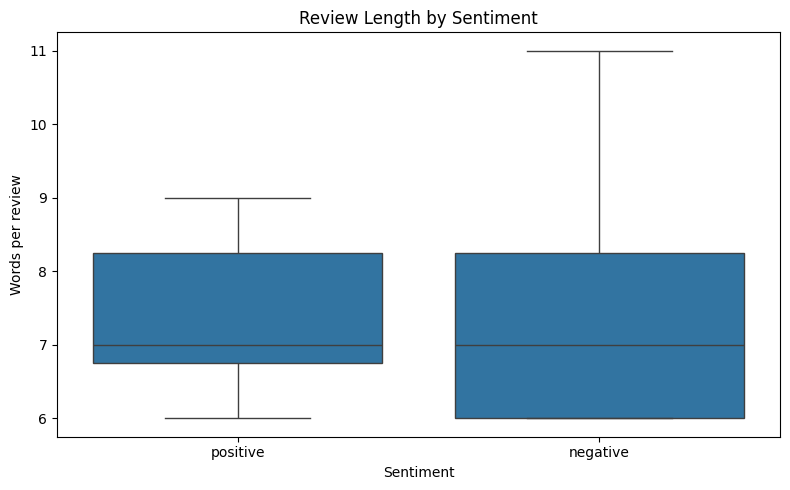

In [4]:
def clean_text(s):
    s = str(s).lower()
    s = re.sub(r'<.*?>', ' ', s)
    s = re.sub(r"[^a-z']", ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

raw_example = df['review'].iloc[0]
print('BEFORE:', raw_example[:500])
df['clean_review'] = df['review'].apply(clean_text)
print('\nAFTER:', df['clean_review'].iloc[0][:500])
df = df[df['clean_review'].str.len() > 0].copy()
df['word_count'] = df['clean_review'].str.split().str.len()
mean_len = df['word_count'].mean()
median_len = df['word_count'].median()
p95_len = df['word_count'].quantile(.95)
print(f'Mean={mean_len:.1f}, median={median_len:.1f}, 95th percentile={p95_len:.1f}')
plt.figure(figsize=(10,5))
plt.hist(df['word_count'], bins=50)
plt.axvline(mean_len, linestyle='--', label=f'Mean {mean_len:.1f}')
plt.axvline(median_len, linestyle='--', label=f'Median {median_len:.1f}')
plt.axvline(p95_len, linestyle='--', label=f'95th percentile {p95_len:.1f}')
plt.title('Distribution of Review Lengths'); plt.xlabel('Words per review'); plt.ylabel('Number of reviews'); plt.legend(); plt.tight_layout()
plt.savefig('plots/length_distribution.png', dpi=150); plt.show()
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='sentiment', y='word_count')
plt.title('Review Length by Sentiment'); plt.xlabel('Sentiment'); plt.ylabel('Words per review'); plt.tight_layout()
plt.savefig('plots/length_by_sentiment.png', dpi=150); plt.show()

In [5]:
y = (df['sentiment'] == 'positive').astype('int32').to_numpy()
texts = df['clean_review'].to_numpy()
X_train_text, X_test_text, y_train, y_test = train_test_split(
    texts, y, test_size=0.2, random_state=42, stratify=y
)
MAX_WORDS = 10000
EMBED_DIM = 32
MAXLEN = max(50, min(300, int(round(p95_len / 10) * 10)))
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_text)
train_seq = tokenizer.texts_to_sequences(X_train_text)
test_seq = tokenizer.texts_to_sequences(X_test_text)
X_train = pad_sequences(train_seq, maxlen=MAXLEN, padding='pre', truncating='pre')
X_test = pad_sequences(test_seq, maxlen=MAXLEN, padding='pre', truncating='pre')
print('MAXLEN:', MAXLEN)
print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_test:', X_test.shape, 'y_test:', y_test.shape)
print('Top words:', sorted(tokenizer.word_index.items(), key=lambda x:x[1])[:10])
print('One review sequence:', train_seq[0][:50])

MAXLEN: 50
X_train: (12, 50) y_train: (12,)
X_test: (4, 50) y_test: (4,)
Top words: [('<OOV>', 1), ('the', 2), ('and', 3), ('film', 4), ('was', 5), ('a', 6), ('this', 7), ('story', 8), ('i', 9), ('movie', 10)]
One review sequence: [23, 11, 12, 7, 4, 24]


**Why `num_words=10000`?** A vocabulary cap reduces parameters and limits rare-word noise. The OOV token represents words outside the retained vocabulary.

**Why pre-padding?** The sequence is padded on the left, so real words occupy the final positions. With pre-truncation, the most recent/final part of a long review is retained.

**Why is text sequential?** “The movie was not good” and “the movie was good, not bad” contain similar words but express different meanings. A bag-of-words representation loses the order needed to distinguish them.

## Task 2 — RNN intuition, ANN vs RNN and forward propagation
**Objective:** Establish an order-blind ANN baseline and verify a manual RNN forward pass.  
**Expected output:** Model summary, manual hidden states, heatmap, Keras verification and comparison.

In [6]:
def build_ann():
    model = Sequential([
        Input(shape=(MAXLEN,)),
        Embedding(MAX_WORDS, EMBED_DIM),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    return model

ann_model = build_ann()
ann_model.summary()
ann_start = time.time()
ann_history = ann_model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)
ann_time = (time.time()-ann_start)/max(1, len(ann_history.epoch))
ann_prob = ann_model.predict(X_test, verbose=0).ravel()
ann_pred = (ann_prob >= .5).astype(int)
ann_metrics = {'Model':'ANN baseline', 'Parameters':ann_model.count_params(), 'Time per Epoch (s)':ann_time,
               'Epochs Trained':len(ann_history.epoch), 'Accuracy':accuracy_score(y_test,ann_pred),
               'Precision':precision_score(y_test,ann_pred,zero_division=0), 'Recall':recall_score(y_test,ann_pred,zero_division=0),
               'F1':f1_score(y_test,ann_pred,zero_division=0), 'ROC-AUC':roc_auc_score(y_test,ann_prob)}
print('ANN test accuracy:', ann_metrics['Accuracy'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 32)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,529 (1.61 MB)

 Trainable params: 422,529 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5000 - loss: 0.6948 - val_accuracy: 0.0000e+00 - val_loss: 0.7624
Epoch 2/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.6000 - loss: 0.6792 - val_accuracy: 0.0000e+00 - val_loss: 0.8258
Epoch 3/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.6000 - loss: 0.6707 - val_accuracy: 0.0000e+00 - val_loss: 0.8852
Epoch 4/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.6000 - loss: 0.6650 - val_accuracy: 0.0000e+00 - val_loss: 0.9343
Epoch 5/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.6000 - loss: 0.6609 - val_accuracy: 0.0000e+00 - val_loss: 0.9709
ANN test accuracy: 0.5


An RNN reads one token at a time and maintains a hidden state summarising what it has read so far. The same weights are reused at each time step, so parameter count does not grow with sequence length.

\(h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b)\)

Here, \(x_t\) is the current input, \(h_{t-1}\) is the previous hidden state, and the matrices and bias are learned parameters. The output can be written as \(y_t=f(W_{hy}h_t+b_y)\).

Manual hidden states:
 [[-3.87642276e-01 -9.54131773e-01  4.04291498e-01]
 [-5.84081354e-01 -1.79948778e-01  4.84723564e-01]
 [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
 [-8.65741745e-01 -5.08259630e-01  7.75117496e-01]]


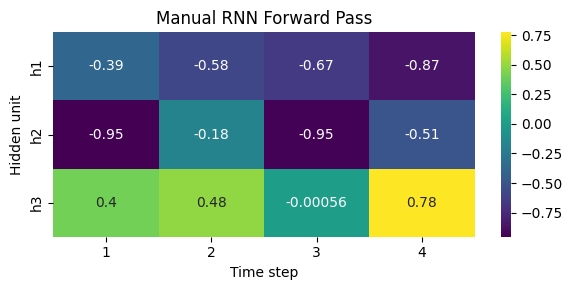

In [7]:
np.random.seed(42)
input_size, hidden_size, steps = 2, 3, 4
Wxh = np.random.randn(hidden_size, input_size) * 0.5
Whh = np.random.randn(hidden_size, hidden_size) * 0.5
b = np.random.randn(hidden_size) * 0.5
sequence = np.random.randn(steps, input_size)
h = np.zeros(hidden_size)
manual_states = []
for t in range(steps):
    h = np.tanh(Wxh @ sequence[t] + Whh @ h + b)
    manual_states.append(h.copy())
manual_states = np.asarray(manual_states)
print('Manual hidden states:\n', manual_states)
plt.figure(figsize=(6,3))
sns.heatmap(manual_states.T, annot=True, cmap='viridis', xticklabels=range(1,steps+1), yticklabels=['h1','h2','h3'])
plt.title('Manual RNN Forward Pass'); plt.xlabel('Time step'); plt.ylabel('Hidden unit'); plt.tight_layout()
plt.savefig('plots/rnn_forward_heatmap.png', dpi=150); plt.show()

In [8]:
rnn_check = SimpleRNN(hidden_size, return_sequences=True, use_bias=True, input_shape=(steps,input_size))
_ = rnn_check(np.zeros((1,steps,input_size), dtype=np.float32))
rnn_check.set_weights([Wxh.T.astype('float32'), Whh.T.astype('float32'), b.astype('float32')])
keras_states = rnn_check(sequence[np.newaxis,:,:].astype('float32')).numpy()[0]
print('Manual matches Keras:', np.allclose(manual_states, keras_states, atol=1e-5))
print('SimpleRNN(64) params on embedding 32:', 64*(32+64+1))

Manual matches Keras: True
SimpleRNN(64) params on embedding 32: 6208


| Feature | ANN baseline | RNN |
|---|---|---|
| Input handling | Fixed positions flattened | Processes one time step at a time |
| Word order | Does not model sequential order explicitly | Order-aware |
| Weight sharing | Position-specific downstream weights | Same recurrent weights at every step |
| Parameters vs sequence length | Flattened dense layer grows with MAXLEN | Recurrent cell count is independent of MAXLEN |
| Earlier words | No recurrent memory | Compressed into hidden state |
| Typical use | Tabular/fixed-size inputs | Text, speech and time series |

## Task 3 — RNN types and SimpleRNN sentiment model
**Objective:** Demonstrate common sequence mappings and train/evaluate a many-to-one SimpleRNN.  
**Expected output:** Shapes, training curves, classification metrics, confusion matrix and embeddings.

In [9]:
dummy = tf.zeros((4,10,8))
one_to_one = Dense(1)(tf.zeros((4,8)))
one_to_many = Sequential([Input(shape=(8,)), RepeatVector(10), SimpleRNN(16, return_sequences=True)])(tf.zeros((4,8)))
many_to_one = SimpleRNN(16, return_sequences=False)(dummy)
many_to_many = SimpleRNN(16, return_sequences=True)(dummy)
shape_table = pd.DataFrame([
    ['One-to-one','(4, 8)','(4, 1)','Not applicable','Single-vector classification'],
    ['One-to-many','(4, 8)','(4, 10, 16)','True','Image caption generation'],
    ['Many-to-one','(4, 10, 8)','(4, 16)','False','Sentiment analysis'],
    ['Many-to-many','(4, 10, 8)','(4, 10, 16)','True','Sequence tagging']
], columns=['Type','Input shape','Output shape','return_sequences','Example'])
display(shape_table)

,Type,Input shape,Output shape,return_sequences,Example
0,One-to-one,"(4, 8)","(4, 1)",Not applicable,Single-vector classification
1,One-to-many,"(4, 8)","(4, 10, 16)",True,Image caption generation
2,Many-to-one,"(4, 10, 8)","(4, 16)",False,Sentiment analysis
3,Many-to-many,"(4, 10, 8)","(4, 10, 16)",True,Sequence tagging


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 32)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Expected SimpleRNN params: 6208
Epoch 1/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.7000 - loss: 0.6804 - val_accuracy: 0.5000 - val_loss: 0.7183
Epoch 2/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.6000 - loss: 0.6554 - val_accuracy: 0.0000e+00 - val_loss: 0.7926
Epoch 3/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.6000 - loss: 0.6367 - val_accuracy: 0.0000e+00 - val_loss: 0.8536
Epoch 4/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.6000 - loss: 0.6217 - val_accuracy: 0.0000e+00 - val_loss: 0.8775
              precision    recall  f1-score   support

    negative       0.50      1.00      0.67         2
    positive       0.00      0.00      0.00         2

    accuracy                           0.50         4
   macro avg       0.25      0.50      0.33         4
weighted avg       0.25      0.50      0.33         4



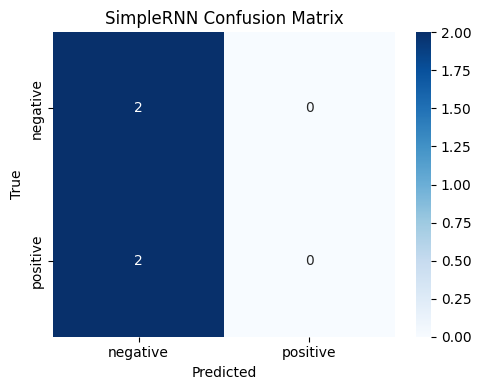

In [10]:
def build_model(cell_type='rnn', units=64, maxlen=None):
    maxlen = MAXLEN if maxlen is None else maxlen
    layer_map = {'rnn': SimpleRNN, 'lstm': LSTM, 'gru': GRU}
    if cell_type not in layer_map:
        raise ValueError('cell_type must be rnn, lstm, or gru')
    model = Sequential([
        Input(shape=(maxlen,)),
        Embedding(MAX_WORDS, EMBED_DIM),
        layer_map[cell_type](units),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    return model

results = {}
histories = {}
probabilities = {}
models = {}
def train_evaluate(name, model, epochs=15):
    start = time.time()
    history = model.fit(X_train, y_train, epochs=epochs, batch_size=64, validation_split=0.1,
                        callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
                        verbose=1)
    elapsed = time.time()-start
    prob = model.predict(X_test, verbose=0).ravel()
    pred = (prob >= .5).astype(int)
    try: auc = roc_auc_score(y_test, prob)
    except ValueError: auc = float('nan')
    row = {'Model':name, 'Parameters':model.count_params(), 'Time per Epoch (s)':elapsed/max(1,len(history.epoch)),
           'Epochs Trained':len(history.epoch), 'Accuracy':accuracy_score(y_test,pred),
           'Precision':precision_score(y_test,pred,zero_division=0), 'Recall':recall_score(y_test,pred,zero_division=0),
           'F1':f1_score(y_test,pred,zero_division=0), 'ROC-AUC':auc}
    results[name] = row; histories[name] = history; probabilities[name] = prob; models[name] = model
    print(classification_report(y_test,pred,target_names=['negative','positive'],zero_division=0))
    plt.figure(figsize=(5,4))
    sns.heatmap(confusion_matrix(y_test,pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=['negative','positive'], yticklabels=['negative','positive'])
    plt.title(f'{name} Confusion Matrix'); plt.xlabel('Predicted'); plt.ylabel('True'); plt.tight_layout()
    plt.savefig(f"plots/confusion_{name.lower().replace(' ','_')}.png", dpi=150); plt.show()
    return row

rnn_model = build_model('rnn', units=64)
rnn_model.summary()
print('Expected SimpleRNN params:', 64*(EMBED_DIM+64+1))
rnn_row = train_evaluate('SimpleRNN', rnn_model)

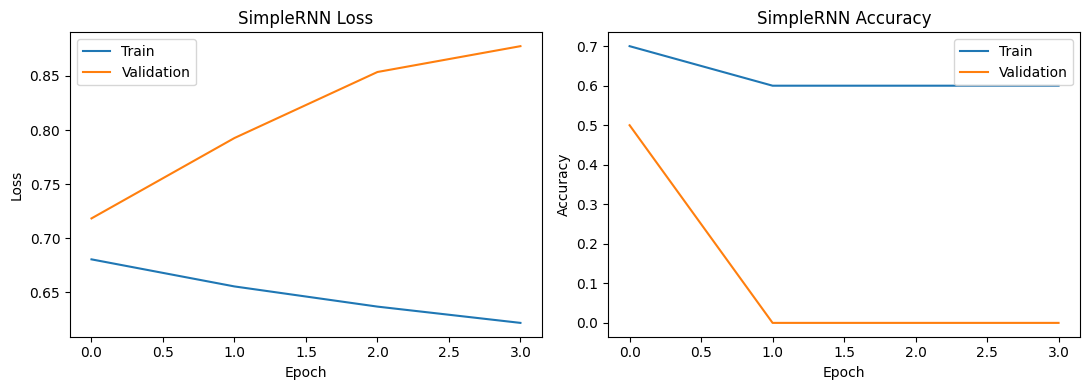

Embedding weight shape: (10000, 32)
good [-0.01308266  0.03665945  0.01101379 -0.03558376  0.02681808  0.04040506
 -0.00350728 -0.03029076]


In [11]:
def plot_history(history, name):
    fig, axes = plt.subplots(1,2,figsize=(11,4))
    axes[0].plot(history.history['loss'], label='Train')
    axes[0].plot(history.history['val_loss'], label='Validation')
    axes[0].set_title(f'{name} Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()
    axes[1].plot(history.history['accuracy'], label='Train')
    axes[1].plot(history.history['val_accuracy'], label='Validation')
    axes[1].set_title(f'{name} Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()
    plt.tight_layout(); plt.savefig(f"plots/training_curves_{name.lower().replace(' ','_')}.png", dpi=150); plt.show()
plot_history(histories['SimpleRNN'], 'SimpleRNN')
print('Embedding weight shape:', rnn_model.layers[0].get_weights()[0].shape)
for word in ['good','bad']:
    idx = tokenizer.word_index.get(word)
    if idx is not None and idx < MAX_WORDS:
        print(word, rnn_model.layers[0].get_weights()[0][idx][:8])

## Task 4 — Backpropagation through time and RNN problems
**Objective:** Explain gradient flow and demonstrate how sequence length and clipping affect training.  
**Expected output:** BPTT explanation, gradient plot, sequence-length experiment and clipping comparison.

### BPTT and gradient problems
Backpropagation Through Time unrolls the recurrent network across its time steps. The loss gradient travels backwards through each step, and the gradient for a shared weight sums contributions from all steps. The gradient to an early hidden state contains a product of recurrent Jacobian terms, approximately:

\(\frac{\partial L}{\partial h_1}=\frac{\partial L}{\partial h_T}\prod_{t=2}^{T}\left(W_{hh}^{T}\operatorname{diag}(1-h_t^2)\right)\)

If repeated factors have magnitude below one, gradients shrink exponentially (vanishing gradients). If they grow above one, gradients can explode and cause unstable loss or NaNs. Gradient clipping limits exploding gradients but does not solve vanishing gradients. SimpleRNNs often struggle to retain useful information across long sequences.

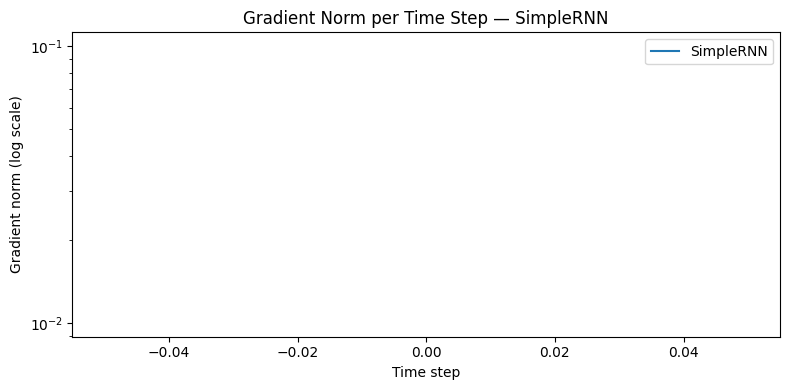

In [12]:
def gradient_norms(model, sample_x, sample_y):
    embedding = model.layers[0]
    recurrent = model.layers[1]
    head = model.layers[-1]
    with tf.GradientTape() as tape:
        emb = embedding(sample_x)
        H = recurrent(emb, training=False) if isinstance(recurrent, (SimpleRNN,LSTM,GRU)) else recurrent(emb)
        tape.watch(H)
        last = H[:, -1, :] if len(H.shape)==3 else H
        pred = head(last, training=False)
        loss = tf.reduce_mean(tf.keras.losses.binary_crossentropy(sample_y, tf.squeeze(pred, axis=-1)))
    grads = tape.gradient(loss, H)
    if len(grads.shape)==3:
        norms = tf.reduce_mean(tf.norm(grads, axis=-1), axis=0).numpy()
    else:
        norms = np.array([float(tf.reduce_mean(tf.norm(grads,axis=-1)).numpy())])
    return norms
sample_x = tf.convert_to_tensor(X_train[:min(64,len(X_train))], dtype=tf.int32)
sample_y = tf.convert_to_tensor(y_train[:len(sample_x)], dtype=tf.float32)
try:
    rnn_norm = gradient_norms(rnn_model, sample_x, sample_y)
    plt.figure(figsize=(8,4)); plt.plot(np.arange(len(rnn_norm)), rnn_norm, label='SimpleRNN')
    plt.yscale('log'); plt.title('Gradient Norm per Time Step — SimpleRNN'); plt.xlabel('Time step'); plt.ylabel('Gradient norm (log scale)')
    plt.legend(); plt.tight_layout(); plt.savefig('plots/gradient_norms_rnn.png', dpi=150); plt.show()
except Exception as e:
    print('Gradient analysis skipped safely:', e)

,MAXLEN,Test Accuracy
0,50,0.5
1,100,0.5
2,200,0.5
3,300,0.5


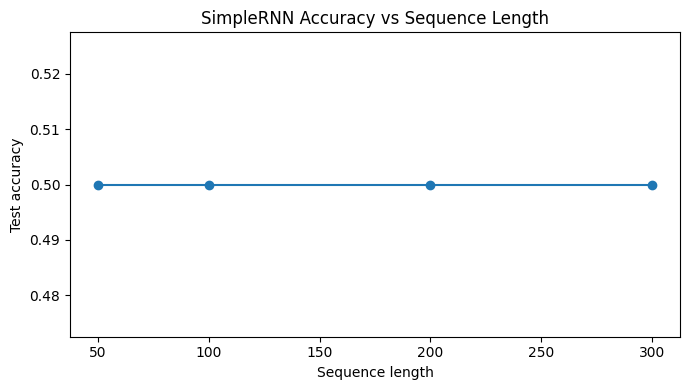

In [13]:
# Sequence-length sensitivity experiment; a short epoch budget keeps the practical manageable.
length_results = []
for length in [50,100,200,300]:
    xtr = pad_sequences(train_seq, maxlen=length, padding='pre', truncating='pre')
    xte = pad_sequences(test_seq, maxlen=length, padding='pre', truncating='pre')
    model_len = build_model('rnn', units=32, maxlen=length)
    hlen = model_len.fit(xtr, y_train, epochs=2, batch_size=64, validation_split=.1, verbose=0)
    p = model_len.predict(xte, verbose=0).ravel()
    length_results.append({'MAXLEN':length, 'Test Accuracy':accuracy_score(y_test,(p>=.5).astype(int))})
length_df = pd.DataFrame(length_results)
display(length_df)
plt.figure(figsize=(7,4)); plt.plot(length_df['MAXLEN'], length_df['Test Accuracy'], marker='o')
plt.title('SimpleRNN Accuracy vs Sequence Length'); plt.xlabel('Sequence length'); plt.ylabel('Test accuracy'); plt.tight_layout()
plt.savefig('plots/accuracy_vs_sequence_length.png', dpi=150); plt.show()

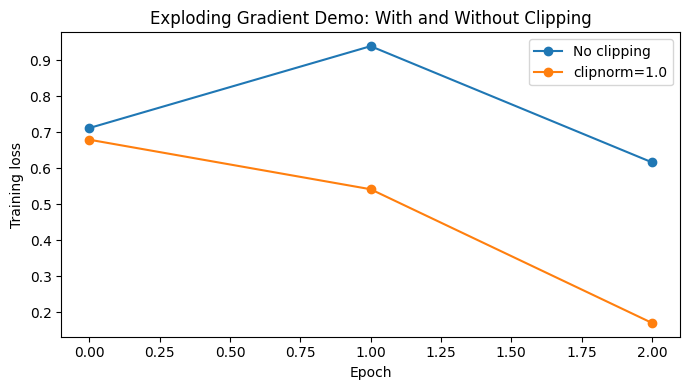

In [14]:
# High learning-rate demo, compared with gradient clipping.
def make_clipping_demo(clipnorm=None):
    m = Sequential([Input(shape=(MAXLEN,)), Embedding(MAX_WORDS, EMBED_DIM), SimpleRNN(32), Dense(1,activation='sigmoid')])
    m.compile(optimizer=Adam(learning_rate=0.05, clipnorm=clipnorm), loss='binary_crossentropy', metrics=['accuracy'])
    return m
loss_curves = {}
for label, clip in [('No clipping',None),('clipnorm=1.0',1.0)]:
    demo_model = make_clipping_demo(clip)
    h = demo_model.fit(X_train, y_train, epochs=3, batch_size=64, validation_split=.1, verbose=0)
    loss_curves[label] = h.history['loss']
plt.figure(figsize=(7,4))
for label, losses in loss_curves.items(): plt.plot(losses, marker='o', label=label)
plt.title('Exploding Gradient Demo: With and Without Clipping'); plt.xlabel('Epoch'); plt.ylabel('Training loss'); plt.legend(); plt.tight_layout()
plt.savefig('plots/gradient_clipping.png', dpi=150); plt.show()

| Problem | Cause | Typical symptom | Remedy |
|---|---|---|---|
| Vanishing gradient | Repeated gradient factors shrink | Early tokens contribute little | LSTM/GRU gates |
| Exploding gradient | Repeated gradient factors grow | Loss spikes or NaNs | Gradient clipping |
| Slow sequential training | Steps processed sequentially | Long training time | Smaller sequences or GPU |
| Short effective memory | Basic recurrent state struggles with long context | Weak long-review performance | Gated recurrent cells |

## Task 5 — LSTM
**Objective:** Explain LSTM gates and train an LSTM using the same split and evaluation method.  
**Expected output:** LSTM theory, parameter verification, training curves and evaluation.

### LSTM cell and why it helps
The cell state \(C_t\) carries information forward. The forget gate \(f_t=\sigma(W_f[h_{t-1},x_t]+b_f)\) controls what to retain; the input gate \(i_t=\sigma(W_i[h_{t-1},x_t]+b_i)\) controls what to write; the candidate \(g_t=\tanh(W_g[h_{t-1},x_t]+b_g)\) proposes new content. The cell update is \(C_t=f_t*C_{t-1}+i_t*g_t\). The output gate \(o_t=\sigma(W_o[h_{t-1},x_t]+b_o)\) controls what to reveal, and \(h_t=o_t*\tanh(C_t)\).

The additive cell-state path can preserve gradients when the forget gate stays near one, helping information survive across more time steps than in a basic SimpleRNN.

Expected LSTM(64) params: 24832


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_8 (Embedding)         │ (None, 50, 32)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.6000 - loss: 0.6929 - val_accuracy: 0.0000e+00 - val_loss: 0.7042
Epoch 2/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.6000 - loss: 0.6905 - val_accuracy: 0.0000e+00 - val_loss: 0.7135
Epoch 3/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.6000 - loss: 0.6880 - val_accuracy: 0.0000e+00 - val_loss: 0.7238
Epoch 4/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.6000 - loss: 0.6855 - val_accuracy: 0.0000e+00 - val_loss: 0.7356
              precision    recall  f1-score   support

    negative       0.50      1.00      0.67         2
    positive       0.00      0.00      0.00         2

    accuracy                           0.50         4
   macro avg       0.25      0.50      0.33         4
weighted avg       0.25      0.50      0.33         4



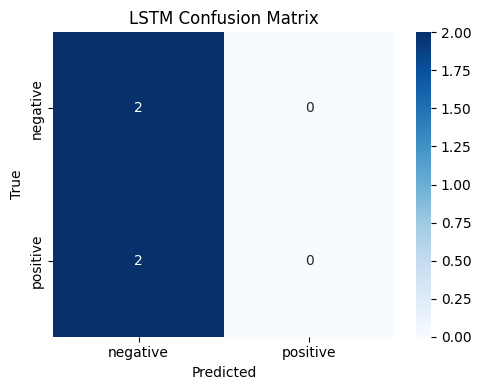

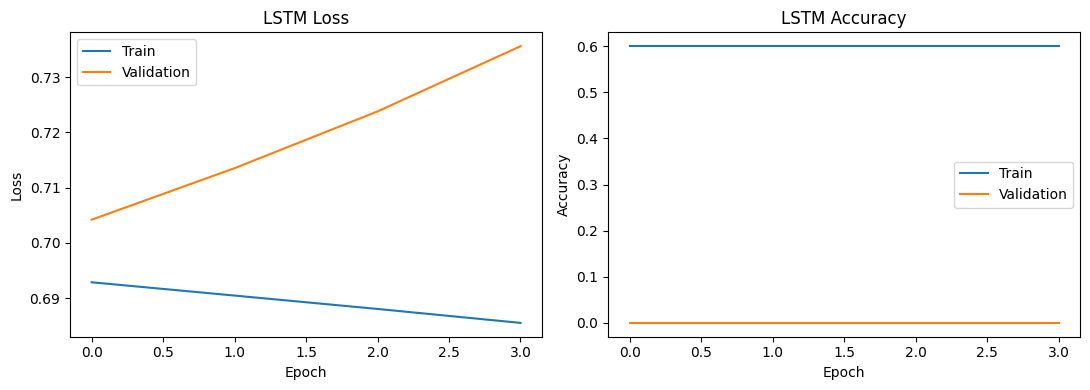

In [15]:
print('Expected LSTM(64) params:', 4*64*(EMBED_DIM+64+1))
lstm_model = build_model('lstm', units=64)
lstm_model.summary()
lstm_row = train_evaluate('LSTM', lstm_model)
plot_history(histories['LSTM'], 'LSTM')

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 0.7000 - loss: 0.6926 - val_accuracy: 0.0000e+00 - val_loss: 0.7147
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step - accuracy: 0.6000 - loss: 0.6886 - val_accuracy: 0.0000e+00 - val_loss: 0.7366
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.6000 - loss: 0.6847 - val_accuracy: 0.0000e+00 - val_loss: 0.7627
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.6000 - loss: 0.6808 - val_accuracy: 0.0000e+00 - val_loss: 0.7957
              precision    recall  f1-score   support

    negative       0.50      1.00      0.67         2
    positive       0.00      0.00      0.00         2

    accuracy                           0.50         4
   macro avg       0.25      0.50      0.33         4
weighted avg       0.25      0.50      0.33         4



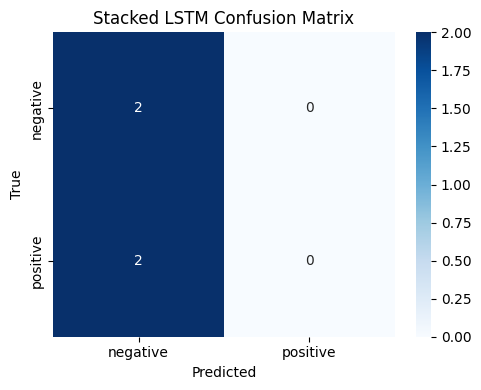

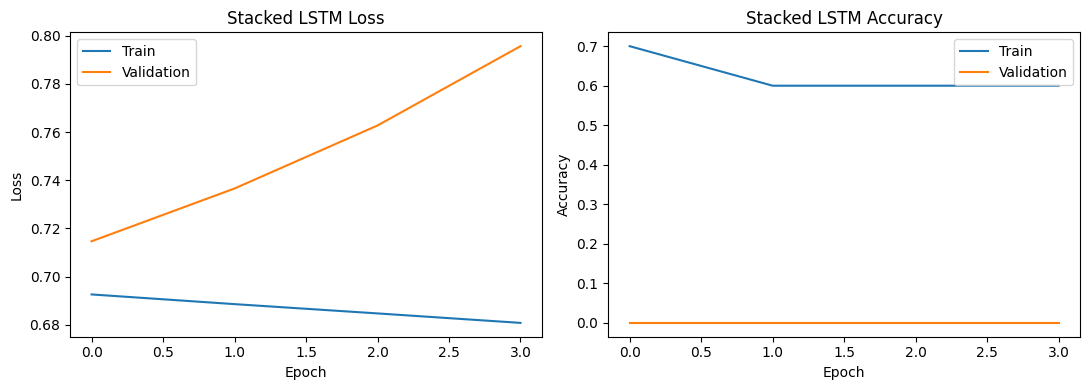

In [16]:
# Two-layer LSTM: first layer returns the full sequence for the next LSTM.
stacked_model = Sequential([
    Input(shape=(MAXLEN,)), Embedding(MAX_WORDS, EMBED_DIM),
    LSTM(64, return_sequences=True), LSTM(32), Dense(1, activation='sigmoid')
])
stacked_model.compile(optimizer=Adam(learning_rate=.001), loss='binary_crossentropy', metrics=['accuracy'])
stacked_row = train_evaluate('Stacked LSTM', stacked_model, epochs=10)
plot_history(histories['Stacked LSTM'], 'Stacked LSTM')

## Task 6 — GRU
**Objective:** Explain the GRU gates and compare a GRU model with SimpleRNN and LSTM.  
**Expected output:** GRU evaluation, model comparisons and hidden-unit sensitivity.

### GRU cell
The update gate is \(z_t=\sigma(W_z[h_{t-1},x_t])\), and the reset gate is \(r_t=\sigma(W_r[h_{t-1},x_t])\). The candidate state is \(\tilde h_t=\tanh(W[r_t*h_{t-1},x_t])\), and the new state is \(h_t=(1-z_t)*h_{t-1}+z_t*\tilde h_t\). The update gate balances old and candidate information; the reset gate controls how much past information is used to form the candidate. Unlike LSTM, GRU has no separate cell state and merges forget/input control into one update gate.

Expected GRU(64) params with reset_after=True: 18816


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_10 (Embedding)        │ (None, 50, 32)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.8000 - loss: 0.6879 - val_accuracy: 0.0000e+00 - val_loss: 0.7075
Epoch 2/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.7000 - loss: 0.6840 - val_accuracy: 0.0000e+00 - val_loss: 0.7192
Epoch 3/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.6000 - loss: 0.6801 - val_accuracy: 0.0000e+00 - val_loss: 0.7315
Epoch 4/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.6000 - loss: 0.6762 - val_accuracy: 0.0000e+00 - val_loss: 0.7445
              precision    recall  f1-score   support

    negative       0.50      1.00      0.67         2
    positive       0.00      0.00      0.00         2

    accuracy                           0.50         4
   macro avg       0.25      0.50      0.33         4
weighted avg       0.25      0.50      0.33         4



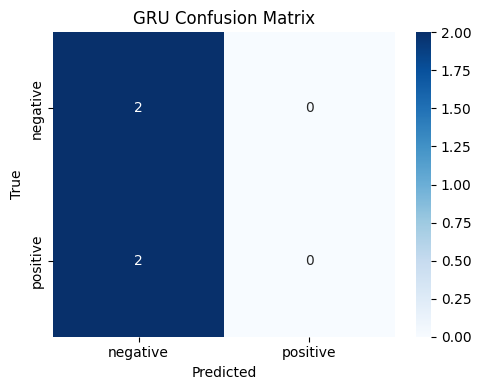

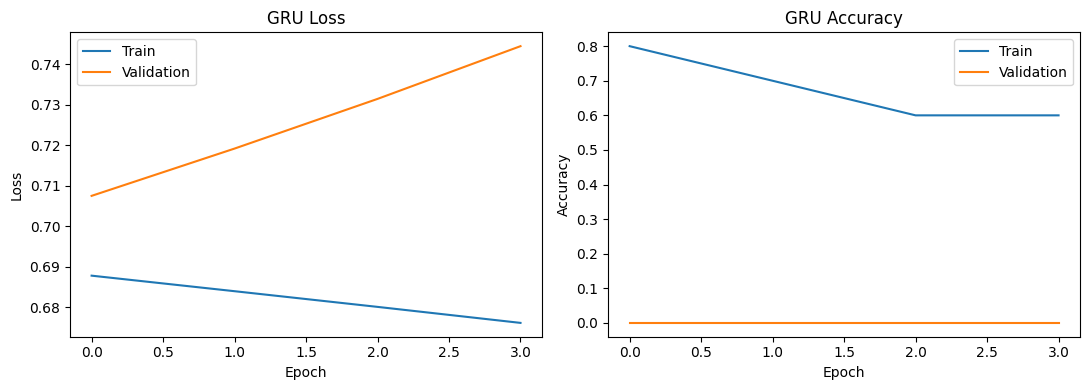

In [17]:
print('Expected GRU(64) params with reset_after=True:', 3*(EMBED_DIM*64 + 64*64 + 2*64))
gru_model = build_model('gru', units=64)
gru_model.summary()
gru_row = train_evaluate('GRU', gru_model)
plot_history(histories['GRU'], 'GRU')

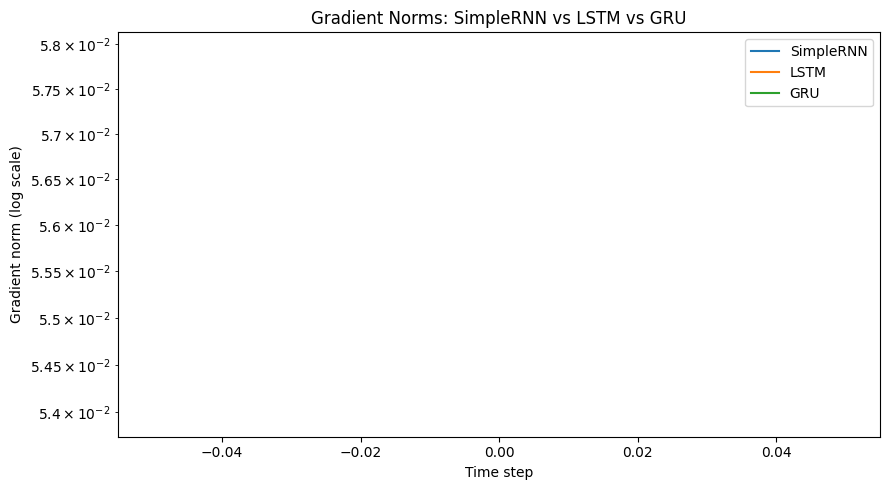

In [18]:
# Compare all three gradient flows on the same sample batch.
gradient_curves = {}
for name, model in [('SimpleRNN',rnn_model),('LSTM',lstm_model),('GRU',gru_model)]:
    try:
        gradient_curves[name] = gradient_norms(model, sample_x, sample_y)
    except Exception as e:
        print(name, 'gradient calculation skipped:', e)
plt.figure(figsize=(9,5))
for name, values in gradient_curves.items():
    plt.plot(np.arange(len(values)), np.maximum(values,1e-12), label=name)
plt.yscale('log'); plt.title('Gradient Norms: SimpleRNN vs LSTM vs GRU')
plt.xlabel('Time step'); plt.ylabel('Gradient norm (log scale)'); plt.legend(); plt.tight_layout()
plt.savefig('plots/gradient_norms_all_cells.png', dpi=150); plt.show()

,Cell,Units,Parameters,Test Accuracy
0,LSTM,32,328353,0.5
1,LSTM,64,344897,0.5
2,LSTM,128,402561,0.5
3,GRU,32,326369,0.5
4,GRU,64,338881,0.5
5,GRU,128,382337,0.5


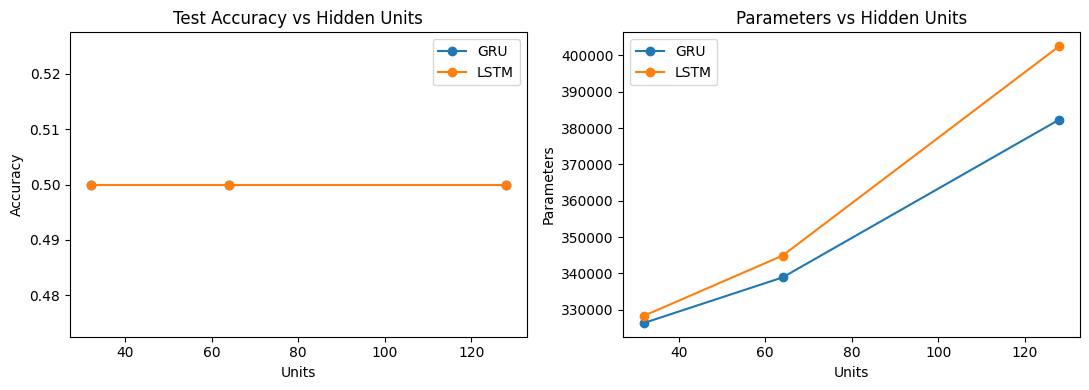

In [19]:
sensitivity = []
for cell in ['lstm','gru']:
    for units in [32,64,128]:
        model = build_model(cell, units=units)
        h = model.fit(X_train, y_train, epochs=2, batch_size=64, validation_split=.1, verbose=0)
        prob = model.predict(X_test, verbose=0).ravel()
        sensitivity.append({'Cell':cell.upper(),'Units':units,'Parameters':model.count_params(),
                            'Test Accuracy':accuracy_score(y_test,(prob>=.5).astype(int))})
sensitivity_df = pd.DataFrame(sensitivity)
display(sensitivity_df)
fig, axes = plt.subplots(1,2,figsize=(11,4))
for cell, group in sensitivity_df.groupby('Cell'):
    axes[0].plot(group['Units'],group['Test Accuracy'],marker='o',label=cell)
    axes[1].plot(group['Units'],group['Parameters'],marker='o',label=cell)
axes[0].set_title('Test Accuracy vs Hidden Units'); axes[0].set_xlabel('Units'); axes[0].set_ylabel('Accuracy'); axes[0].legend()
axes[1].set_title('Parameters vs Hidden Units'); axes[1].set_xlabel('Units'); axes[1].set_ylabel('Parameters'); axes[1].legend()
plt.tight_layout(); plt.savefig('plots/hidden_unit_sensitivity.png',dpi=150); plt.show()

| Feature | LSTM | GRU |
|---|---|---|
| Gates | Forget, input, output plus candidate computation | Update and reset |
| Separate cell state | Yes | No |
| Parameters | Usually more | Usually fewer |
| Training speed | Often slower | Often faster |
| Typical choice | When flexible long-term memory is useful | When a compact, efficient gated model is preferred |

## Task 7 — Final comparison, inference and recommendation
**Objective:** Compare all trained models, inspect errors and provide a reusable inference function.  
**Expected output:** Results table, ROC curves, review-length robustness, misclassified examples, six inference tests and recommendation.

In [20]:
# Include the ANN baseline and the recurrent model results.
results['ANN baseline'] = ann_metrics
results_df = pd.DataFrame(list(results.values()))
display(results_df.style.highlight_max(subset=['Accuracy','Precision','Recall','F1','ROC-AUC'], color='#ffcccc'))
results_df.to_csv('plots/results_table.csv', index=False)
results_df.to_csv('results_table.csv', index=False)

,Model,Parameters,Time per Epoch (s),Epochs Trained,Accuracy,Precision,Recall,F1,ROC-AUC
0,SimpleRNN,326273,1.169788,4,0.500000,0.000000,0.000000,0.000000,0.375000
1,LSTM,344897,1.181107,4,0.500000,0.000000,0.000000,0.000000,0.625000
2,Stacked LSTM,357281,1.898115,4,0.500000,0.000000,0.000000,0.000000,0.625000
3,GRU,338881,1.374184,4,0.500000,0.000000,0.000000,0.000000,0.125000
4,ANN baseline,422529,0.660323,5,0.500000,0.000000,0.000000,0.000000,0.125000


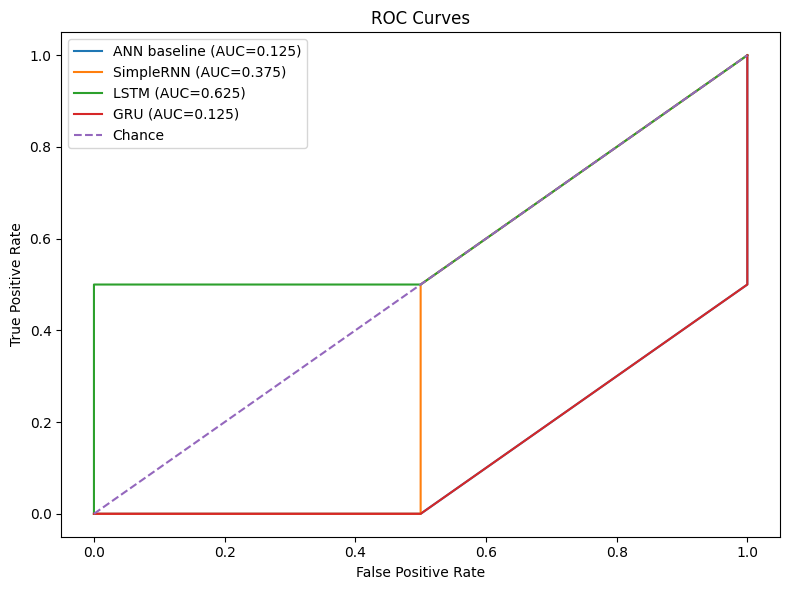

In [21]:
plt.figure(figsize=(8,6))
roc_entries = [('ANN baseline', ann_prob)]
roc_entries += [(name, probabilities[name]) for name in ['SimpleRNN','LSTM','GRU'] if name in probabilities]
for name, prob in roc_entries:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr,tpr,label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],linestyle='--',label='Chance')
plt.title('ROC Curves'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend(); plt.tight_layout()
plt.savefig('plots/roc_curves.png',dpi=150); plt.show()

,Length group,Model,Accuracy,Count
0,Short (<100),SimpleRNN,0.5,4
1,Short (<100),LSTM,0.5,4


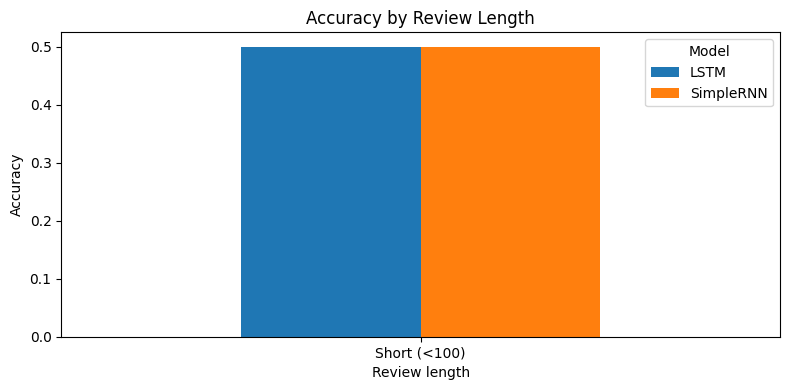

In [22]:
# Review-length robustness: best recurrent model chosen by ROC-AUC among available models.
candidate_names = [n for n in ['SimpleRNN','LSTM','GRU'] if n in probabilities]
best_name = max(candidate_names, key=lambda n: results[n]['ROC-AUC'])
best_model = models[best_name]
length_masks = {
    'Short (<100)': df.loc[X_test_text if False else [], 'word_count'] if False else None
}
test_lengths = np.array([len(str(t).split()) for t in X_test_text])
bins = [('Short (<100)', test_lengths < 100), ('Medium (100-250)', (test_lengths >= 100)&(test_lengths <= 250)), ('Long (>250)', test_lengths > 250)]
robust_rows = []
for label, mask in bins:
    if mask.sum() == 0:
        continue
    for name in ['SimpleRNN', best_name]:
        prob = probabilities[name][mask]
        pred = (prob >= .5).astype(int)
        robust_rows.append({'Length group':label,'Model':name,'Accuracy':accuracy_score(y_test[mask],pred),'Count':int(mask.sum())})
robust_df = pd.DataFrame(robust_rows)
display(robust_df)
if not robust_df.empty:
    pivot = robust_df.pivot(index='Length group',columns='Model',values='Accuracy')
    pivot.plot(kind='bar',figsize=(8,4))
    plt.title('Accuracy by Review Length'); plt.xlabel('Review length'); plt.ylabel('Accuracy'); plt.xticks(rotation=0); plt.tight_layout()
    plt.savefig('plots/accuracy_by_length.png',dpi=150); plt.show()

In [23]:
# Error analysis for best recurrent model.
best_prob = probabilities[best_name]
best_pred = (best_prob >= .5).astype(int)
errors = pd.DataFrame({'text':X_test_text, 'true':y_test, 'pred':best_pred, 'probability':best_prob})
fp = errors[(errors.true==0)&(errors.pred==1)].head(4)
fn = errors[(errors.true==1)&(errors.pred==0)].head(4)
error_examples = pd.concat([fp,fn]).copy()
error_examples['true_label'] = error_examples['true'].map({0:'negative',1:'positive'})
error_examples['predicted_label'] = error_examples['pred'].map({0:'negative',1:'positive'})
display(error_examples[['true_label','predicted_label','probability','text']])

,true_label,predicted_label,probability,text
1,positive,negative,0.493752,i loved the story and the excellent performances
3,positive,negative,0.490781,a clever funny and entertaining story


In [ ]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=MAXLEN, padding='pre', truncating='pre')
    probability = float(best_model.predict(padded, verbose=0)[0][0])
    label = 'positive' if probability >= .5 else 'negative'
    return label, probability

custom_sentences = [
    'I absolutely loved this wonderful movie',
    'This was a terrible and boring film',
    'This film is not good',
    'I cannot say it was not enjoyable',
    'Oh wonderful, another two hours of boredom',
    'Nice'
]
inference_rows = []
for sentence in custom_sentences:
    label, probability = predict_sentiment(sentence)
    inference_rows.append({'Sentence':sentence,'Predicted sentiment':label,'Positive probability':round(probability,4)})
display(pd.DataFrame(inference_rows))

,Sentence,Predicted sentiment,Positive probability
0,I absolutely loved this wonderful movie,negative,0.4952
1,This was a terrible and boring film,negative,0.4944
2,This film is not good,negative,0.4941
3,I cannot say it was not enjoyable,negative,0.4904
4,"Oh wonderful, another two hours of boredom",negative,0.4894
5,Nice,negative,0.4918
